In [1]:
# Theory

# A decision tree is a supervised learning model that predicts using a sequence of rules. Each
# internal node checks a feature, and each branch represents the result of that check. A leaf
# node gives the predicted class for records that reach it. The training algorithm chooses
# splits that make the resulting groups more homogeneous. Entropy measures class uncertainty; a
# node containing only one class has zero entropy. Information gain is the reduction in entropy
# produced by a split.

# The Iris dataset contains four flower measurements and three species labels. The dataset is
# divided into training and testing portions before learning the rules. Stratification keeps
# approximately the same class proportions in both portions. The model is limited to a maximum
# depth of three to keep the tree easy to interpret. A depth limit can reduce overfitting,
# although too small a tree may underfit.

# Accuracy measures the percentage of correctly classified test flowers. The confusion matrix
# displays correct predictions and mistakes for each class. Precision measures correctness among
# predictions assigned to a class. Recall measures how many members of a class were successfully
# identified. F1 combines precision and recall into a single score. Feature importance
# summarizes the contribution of features to impurity reduction. The plotted tree displays
# learned thresholds and the class distribution at its nodes. Trees are easy to explain but can
# change noticeably when the training data changes.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [3]:
# Load the built-in Iris flower dataset
iris = load_iris()
X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = iris.target
print("First five records:\n", X.head())
print("Dataset shape:", X.shape)
print("Flower classes:", iris.target_names)

First five records:
    sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2
Dataset shape: (150, 4)
Flower classes: ['setosa' 'versicolor' 'virginica']


In [4]:
# Divide the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

In [5]:
# Train a small decision tree using entropy
model = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42)
model.fit(X_train, y_train)
prediction = model.predict(X_test)

In [6]:
# Evaluate predictions on unseen flowers
print("Accuracy:", accuracy_score(y_test, prediction) * 100)
print("Confusion Matrix:\n", confusion_matrix(y_test, prediction))
print(classification_report(y_test, prediction, target_names=iris.target_names))
importance = pd.Series(model.feature_importances_, index=X.columns)
print("Feature Importance:\n", importance)
print("First five predictions:", iris.target_names[prediction[:5]])
print("Actual classes:", iris.target_names[y_test[:5]])

Accuracy: 96.66666666666667
Confusion Matrix:
 [[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

Feature Importance:
 sepal length (cm)    0.000000
sepal width (cm)     0.000000
petal length (cm)    0.686546
petal width (cm)     0.313454
dtype: float64
First five predictions: ['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa']
Actual classes: ['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa']


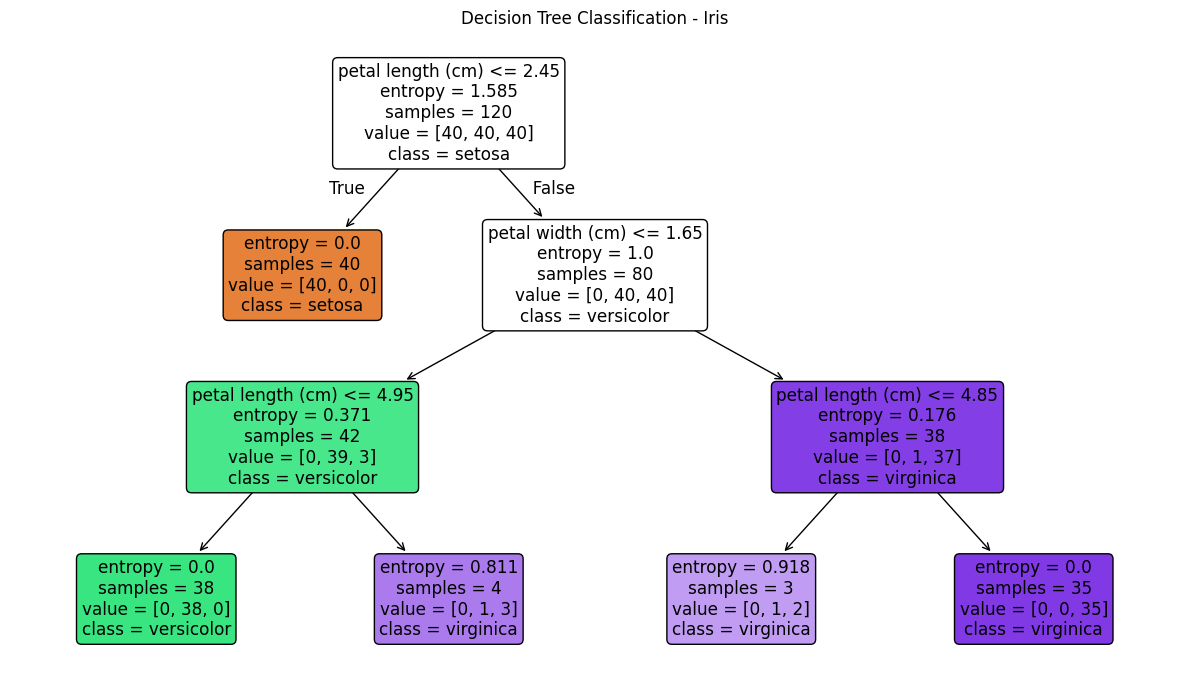

In [7]:
# Display the learned decision rules
plt.figure(figsize=(12, 7))
plot_tree(model, feature_names=iris.feature_names,
          class_names=iris.target_names, filled=True, rounded=True)
plt.title("Decision Tree Classification - Iris")
plt.tight_layout()
plt.show()